#### Aggregazione dei dati grezzi 

In [13]:
import duckdb
from pathlib import Path

# il notebook gira da src/: risali alla root del repo (quella che contiene data/)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw").is_dir())
RAW = ROOT / "data/raw"
PROCESSED = ROOT / "data/processed"
PROCESSED.mkdir(parents=True, exist_ok=True)

TICKER_FROM_FILENAME = r"replace(regexp_extract(filename, '([^/\\]+)\.parquet$', 1), '_', ' ')"

# per ogni cartella: come ricavare ticker e timestamp, quali colonne tenere
# il timestamp viene poi diviso in due campi: date (DATE) e time (TIME)
DATASETS = {
    # i minuti grezzi sono in UTC: li porto all'ora di New York (apertura 09:30, ora legale gestita)
    "intraday_1m": dict(
        ticker=TICKER_FROM_FILENAME,
        ts="timezone('America/New_York', timezone('UTC', time))",
        cols="open, high, low, close, volume, n_events",
        dedup=False,
    ),
    # dati giornalieri: l'orario è sempre 00:00:00
    "daily": dict(
        ticker=TICKER_FROM_FILENAME,
        ts="date",
        cols="PX_LAST, PX_VOLUME, TOT_RETURN_INDEX_GROSS_DVDS",
        dedup=False,
    ),
    # il ticker è già una colonna; i file *_2023_2023 ripetono righe già presenti in *_2006_2026
    "sentiment": dict(
        ticker="ticker",
        ts="date",
        cols="* EXCLUDE (ticker, date, filename)",
        dedup=True,
    ),
}

con = duckdb.connect()
con.execute("SET memory_limit='6GB'")
con.execute("SET preserve_insertion_order=false")

for name, cfg in DATASETS.items():
    src = RAW / name
    out = PROCESSED / f"{name}_all.parquet"
    distinct = "DISTINCT ON (ticker, date, time)" if cfg["dedup"] else ""

    # subquery: evita conflitti tra i nuovi nomi date/time e le colonne grezze omonime
    con.execute(f"""
    COPY (
        SELECT {distinct}
            ticker,
            CAST(ts AS DATE) AS date,
            CAST(ts AS TIME) AS time,
            * EXCLUDE (ticker, ts)
        FROM (
            SELECT {cfg['ticker']} AS ticker, {cfg['ts']} AS ts, {cfg['cols']}
            FROM read_parquet('{src.as_posix()}/*.parquet', filename=true)
        )
        ORDER BY ticker, date, time
    ) TO '{out.as_posix()}' (FORMAT PARQUET, COMPRESSION ZSTD, ROW_GROUP_SIZE 500000)
    """)

    # verifica
    print(f"=== {name} ===")
    print(con.sql(f"""
        SELECT COUNT(*) AS righe,
               COUNT(DISTINCT ticker) AS ticker,
               MIN(date) AS date_min,
               MAX(date) AS date_max,
               MIN(time) AS time_min,
               MAX(time) AS time_max
        FROM '{out.as_posix()}'
    """).df())

    print(con.sql(f"""
        SELECT COUNT(*) AS duplicati FROM (
            SELECT ticker, date, time FROM '{out.as_posix()}'
            GROUP BY 1,2,3 HAVING COUNT(*) > 1
        )
    """).df())

    print("file sorgente:", len(list(src.glob("*.parquet"))))

=== intraday_1m ===
      righe  ticker   date_min   date_max  time_min  time_max
0  13448193     503 2026-06-16 2026-10-30  09:30:00  15:59:00
   duplicati
0          0
file sorgente: 503
=== daily ===
     righe  ticker   date_min   date_max  time_min  time_max
0  2178887     503 2006-11-02 2026-11-02  00:00:00  00:00:00
   duplicati
0          0
file sorgente: 503
=== sentiment ===
     righe  ticker   date_min   date_max  time_min  time_max
0  3858010     503 2006-01-01 2026-12-31  00:00:00  00:00:00
   duplicati
0          0
file sorgente: 506


#### Estrazione feature da file parquet

In [14]:
# indipendente dalla cella precedente: legge solo lo schema, senza caricare i dati
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw").is_dir())
PROCESSED = ROOT / "data/processed"

for name in ["intraday_1m", "daily", "sentiment"]:
    path = PROCESSED / f"{name}_all.parquet"
    print(f"=== {name} ===")
    print(duckdb.sql(f"DESCRIBE SELECT * FROM '{path.as_posix()}'").df()[["column_name", "column_type"]].to_string(index=False))
    print()

=== intraday_1m ===
column_name column_type
     ticker     VARCHAR
       date        DATE
       time        TIME
       open      DOUBLE
       high      DOUBLE
        low      DOUBLE
      close      DOUBLE
     volume      BIGINT
   n_events      BIGINT

=== daily ===
                column_name column_type
                     ticker     VARCHAR
                       date        DATE
                       time        TIME
                    PX_LAST      DOUBLE
                  PX_VOLUME      DOUBLE
TOT_RETURN_INDEX_GROSS_DVDS      DOUBLE

=== sentiment ===
                 column_name column_type
                      ticker     VARCHAR
                        date        DATE
                        time        TIME
    NEWS_SENTIMENT_DAILY_AVG      DOUBLE
    NEWS_POS_SENTIMENT_COUNT      DOUBLE
    NEWS_NEG_SENTIMENT_COUNT      DOUBLE
NEWS_NEUTRAL_SENTIMENT_COUNT      DOUBLE
      NEWS_PUBLICATION_COUNT      DOUBLE
   NEWS_HEAT_PUB_DNUMSTORIES      DOUBLE
          NEWS_H

#### Statistiche descrittive per colonna

In [15]:
# per ogni file in processed e per ogni colonna: tipo, min, max, valori unici (approssimati),
# media, deviazione standard, quartili q25/q50/q75 (approssimati), righe totali, % di null
for path in sorted(PROCESSED.glob("*.parquet")):
    print(f"=== {path.stem} ===")
    display(duckdb.sql(f"SUMMARIZE SELECT * FROM '{path.as_posix()}'").df())

=== daily_all ===


,column_name,column_type,min,max,approx_unique,avg,std,q25,q50,q75,count,null_percentage
0,ticker,VARCHAR,A UN Equity,ZTS UN Equity,513,NaN,NaN,NaN,NaN,NaN,2178887,0.00
1,date,DATE,2006-11-02,2026-11-02,5087,2017-06-09 01:33:07.820204,NaN,2012-08-13,2017-09-27,2022-05-30,2178887,0.00
2,time,TIME,00:00:00,00:00:00,1,00:00:00,NaN,00:00:00,00:00:00,00:00:00,2178887,0.00
3,PX_LAST,DOUBLE,0.1349,9924.4,966291,95.8138448252094,227.9005725261978,24.14519535702412,48.79005940309743,102.33474359753221,2178887,0.01
4,PX_VOLUME,DOUBLE,1.0,1643098436.0,1313975,2353576.2391139125,13294400.64644458,327763.45735276735,723683.5128986717,1670988.727008135,2178887,0.00
5,TOT_RETURN_INDEX_GROSS_DVDS,DOUBLE,0.1475,9924.4,1144139,129.9195176765121,252.21597565499087,36.26273826953205,71.88971539848501,148.29000073665506,2178887,0.01


=== intraday_1m_all ===


,column_name,column_type,min,max,approx_unique,avg,std,q25,q50,q75,count,null_percentage
0,ticker,VARCHAR,A UN Equity,ZTS UN Equity,513,NaN,NaN,NaN,NaN,NaN,13448193,0.0
1,date,DATE,2026-06-16,2026-10-30,100,2026-08-24 03:07:30.75299,NaN,2026-07-21,2026-08-24,2026-09-29,13448193,0.0
2,time,TIME,09:30:00,15:59:00,400,12:47:03.352608,NaN,11:04:13.016909,12:46:22.858191,14:31:11.18203,13448193,0.0
3,open,DOUBLE,6.635,6887.95,284518,216.3842562774813,291.41716320398865,70.36396923190489,131.10916509323863,267.8673177897047,13448193,0.0
4,high,DOUBLE,6.64,6888.18,285873,216.46057534302633,291.52233066535524,70.35005127244942,131.15044931000568,267.6835207077457,13448193,0.0
5,low,DOUBLE,6.61,6887.95,273704,216.30644954337077,291.3093212043843,70.34330693055547,130.8723432349212,267.44777182389356,13448193,0.0
6,close,DOUBLE,6.63,6888.18,283142,216.38299897354315,291.4145138369517,70.64167195812212,130.6983007078875,267.31573197957755,13448193,0.0
7,volume,BIGINT,10,105122934,102563,3724.3699351280875,104542.33781577012,200,497,1343,13448193,0.0
8,n_events,BIGINT,1,11841,2764,14.747338917577997,53.0699347659463,2,5,11,13448193,0.0


=== sentiment_all ===


,column_name,column_type,min,max,approx_unique,avg,std,q25,q50,q75,count,null_percentage
0,ticker,VARCHAR,A UN Equity,ZTS UN Equity,513,NaN,NaN,NaN,NaN,NaN,3858010,0.00
1,date,DATE,2006-01-01,2026-12-31,7729,2016-07-01 12:00:00,NaN,2011-04-02,2016-07-03,2021-09-29,3858010,0.00
2,time,TIME,00:00:00,00:00:00,1,00:00:00,NaN,00:00:00,00:00:00,00:00:00,3858010,0.00
3,NEWS_SENTIMENT_DAILY_AVG,DOUBLE,-134217.7,1.0,19718,-0.050992257047699795,112.48309313082171,-0.013492723452963854,0.0,0.11565204814990859,3858010,63.10
4,NEWS_POS_SENTIMENT_COUNT,DOUBLE,0.0,900.0,357,1.7770252259589585,8.024636895473824,0.0,0.0,1.0,3858010,63.15
5,NEWS_NEG_SENTIMENT_COUNT,DOUBLE,0.0,1535.0,400,1.673490727881709,9.232472910197163,0.0,0.0,1.0,3858010,65.10
6,NEWS_NEUTRAL_SENTIMENT_COUNT,DOUBLE,0.0,5929.0,914,9.385949261374124,35.814508105596936,0.0,1.9999982240012855,5.99965098904493,3858010,62.23
7,NEWS_PUBLICATION_COUNT,DOUBLE,0.0,29772.0,3565,73.32048518790262,209.14595834300636,12.257528146946255,25.69051341208779,58.119013784315875,3858010,61.49
8,NEWS_HEAT_PUB_DNUMSTORIES,DOUBLE,1.0,21156.0,4090,62.2248461315583,214.74561865395862,6.2185637354518475,16.548863638879418,43.07487472815202,3858010,46.06
9,NEWS_HEAT_PUB_DAVG,DOUBLE,0.0,4.0,8960,0.571946385425531,0.571855125469026,0.16608257537383908,0.39814408508086446,0.8224244183524284,3858010,43.23


#### Caricamento in pandas e controlli standard

In [16]:
import pandas as pd

# pd.read_parquet richiede pyarrow, che nel kernel non è installato: carico con DuckDB, già ordinato
# ticker e time hanno pochi valori distinti ripetuti milioni di volte: come category occupano molta meno memoria
def load(name):
    path = (PROCESSED / f"{name}_all.parquet").as_posix()
    df = duckdb.sql(f"SELECT * FROM '{path}' ORDER BY ticker, date, time").df()
    return df.astype({"ticker": "category", "time": "category"})

dfs = {name: load(name) for name in ["intraday_1m", "daily", "sentiment"]}
intraday, daily, sentiment = dfs["intraday_1m"], dfs["daily"], dfs["sentiment"]

# Bloomberg usa -134217.7 come segnaposto per un dato non disponibile: lo tratto come mancante
SENTINEL = -134217.7
num = sentiment.select_dtypes("number").columns
print("segnaposto -134217.7 nel sentiment, convertiti in NaN:", (sentiment[num] == SENTINEL).sum()[lambda s: s > 0].to_dict())
sentiment[num] = sentiment[num].mask(sentiment[num] == SENTINEL)

for name, df in dfs.items():
    rows_per_ticker = df.groupby("ticker", observed=True).size()
    print(f"\n=== {name} ===")
    print(f"righe: {len(df):,} | colonne: {df.shape[1]} | memoria: {df.memory_usage(deep=True).sum() / 1e6:,.0f} MB")
    print(f"periodo: {df['date'].min().date()} → {df['date'].max().date()} | ticker: {df['ticker'].nunique()} "
          f"| righe per ticker: min {rows_per_ticker.min():,}, mediana {rows_per_ticker.median():,.0f}, max {rows_per_ticker.max():,}")
    display(df.head(3))
    # per colonna: tipo, valori presenti, % mancanti, valori distinti
    display(pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "non_null": df.notna().sum(),
        "null_%": (df.isna().mean() * 100).round(2),
        "unici": df.nunique(),
    }))
    print(f"righe duplicate: {df.duplicated().sum()} | chiavi (ticker, date, time) duplicate: {df.duplicated(['ticker', 'date', 'time']).sum()}")
    display(df.describe().T)

segnaposto -134217.7 nel sentiment, convertiti in NaN: {'NEWS_SENTIMENT_DAILY_AVG': 1, 'NEWS_HEAT_READ_DAVG': 208, 'NEWS_HEAT_READ_DMAX': 138}

=== intraday_1m ===
righe: 13,448,193 | colonne: 9 | memoria: 807 MB
periodo: 2026-06-16 → 2026-10-30 | ticker: 503 | righe per ticker: min 3,970, mediana 28,271, max 37,440


,ticker,date,time,open,high,low,close,volume,n_events
0,A UN Equity,2026-06-16,09:30:00,130.98,131.00,130.98,131.00,15538,5
1,A UN Equity,2026-06-16,09:34:00,131.29,131.34,131.29,131.34,400,4
2,A UN Equity,2026-06-16,09:35:00,131.80,131.80,131.80,131.80,100,1


,dtype,non_null,null_%,unici
ticker,category,13448193,0.0,503
date,datetime64[us],13448193,0.0,96
time,category,13448193,0.0,390
open,float64,13448193,0.0,281364
high,float64,13448193,0.0,278345
low,float64,13448193,0.0,278397
close,float64,13448193,0.0,280932
volume,int64,13448193,0.0,105457
n_events,int64,13448193,0.0,2768


righe duplicate: 0 | chiavi (ticker, date, time) duplicate: 0


,count,mean,min,25%,50%,75%,max,std
date,13448193,2026-08-24 03:07:30.752991,2026-06-16 00:00:00,2026-07-21 00:00:00,2026-08-24 00:00:00,2026-09-29 00:00:00,2026-10-30 00:00:00,NaN
open,13448193.0,216.384256,6.635,70.59,131.01,268.1,6887.95,291.417163
high,13448193.0,216.460575,6.64,70.61,131.05,268.185,6888.18,291.522331
low,13448193.0,216.30645,6.61,70.57,130.97,268.0,6887.95,291.309321
close,13448193.0,216.382999,6.63,70.59,131.01,268.09,6888.18,291.414514
volume,13448193.0,3724.369935,10.0,200.0,500.0,1340.0,105122934.0,104542.337816
n_events,13448193.0,14.747339,1.0,2.0,5.0,11.0,11841.0,53.069935



=== daily ===
righe: 2,178,887 | colonne: 6 | memoria: 76 MB
periodo: 2006-11-02 → 2026-11-02 | ticker: 503 | righe per ticker: min 19, mediana 5,029, max 5,030


... (5 outputs left out)

,ticker,date,time,NEWS_SENTIMENT_DAILY_AVG,NEWS_POS_SENTIMENT_COUNT,NEWS_NEG_SENTIMENT_COUNT,NEWS_NEUTRAL_SENTIMENT_COUNT,NEWS_PUBLICATION_COUNT,NEWS_HEAT_PUB_DNUMSTORIES,NEWS_HEAT_PUB_DAVG,NEWS_HEAT_PUB_DMAX,NEWS_HEAT_READ_DAVG,NEWS_HEAT_READ_DMAX
0,A UN Equity,2006-01-01,00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,A UN Equity,2006-01-02,00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,A UN Equity,2006-01-03,00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,dtype,non_null,null_%,unici
ticker,category,3858010,0.00,503
date,datetime64[us],3858010,0.00,7670
time,category,3858010,0.00,1
NEWS_SENTIMENT_DAILY_AVG,float64,1423797,63.10,19985
NEWS_POS_SENTIMENT_COUNT,float64,1421829,63.15,365
NEWS_NEG_SENTIMENT_COUNT,float64,1346510,65.10,397
NEWS_NEUTRAL_SENTIMENT_COUNT,float64,1457233,62.23,910
NEWS_PUBLICATION_COUNT,float64,1485610,61.49,3505
NEWS_HEAT_PUB_DNUMSTORIES,float64,2081161,46.06,4101
NEWS_HEAT_PUB_DAVG,float64,2190244,43.23,8745


righe duplicate: 0 | chiavi (ticker, date, time) duplicate: 0


,count,mean,min,25%,50%,75%,max,std
date,3858010,2016-07-01 11:59:59.999999,2006-01-01 00:00:00,2011-04-02 00:00:00,2016-07-01 12:00:00,2021-10-01 00:00:00,2026-12-31 00:00:00,NaN
NEWS_SENTIMENT_DAILY_AVG,1423797.0,0.043275,-1.0,-0.0132,0.0,0.1133,1.0,0.296349
NEWS_POS_SENTIMENT_COUNT,1421829.0,1.777025,0.0,0.0,0.0,1.0,900.0,8.024637
NEWS_NEG_SENTIMENT_COUNT,1346510.0,1.673491,0.0,0.0,0.0,1.0,1535.0,9.232473
NEWS_NEUTRAL_SENTIMENT_COUNT,1457233.0,9.385949,0.0,0.0,2.0,6.0,5929.0,35.814508
NEWS_PUBLICATION_COUNT,1485610.0,73.320485,0.0,12.0,26.0,58.0,29772.0,209.145958
NEWS_HEAT_PUB_DNUMSTORIES,2081161.0,62.224846,1.0,6.0,17.0,43.0,21156.0,214.745619
NEWS_HEAT_PUB_DAVG,2190244.0,0.571946,0.0,0.1667,0.4042,0.833,4.0,0.571855
NEWS_HEAT_PUB_DMAX,2190244.0,1.965913,0.0,1.0,2.0,3.0,4.0,1.173107
NEWS_HEAT_READ_DAVG,1753986.0,0.080932,0.0,0.0,0.0,0.0,4.0,0.342929


#### Controlli sulle serie di prezzi

In [17]:
import numpy as np

# ===== intraday: barre da 1 minuto, prezzi NON aggiustati per split e dividendi =====
print("=== intraday_1m ===")
PX = ["open", "high", "low", "close"]
session_minutes = pd.date_range("09:30", "15:59", freq="min").time  # seduta regolare: 390 minuti
display(pd.Series({
    "prezzi <= 0": (intraday[PX] <= 0).any(axis=1).sum(),
    "volume <= 0": (intraday["volume"] <= 0).sum(),
    "high < max(open, close)": (intraday["high"] < np.maximum(intraday["open"], intraday["close"])).sum(),
    "low > min(open, close)": (intraday["low"] > np.minimum(intraday["open"], intraday["close"])).sum(),
    "high < low": (intraday["high"] < intraday["low"]).sum(),
    "barre fuori da 09:30-15:59": (~intraday["time"].isin(session_minutes)).sum(),
}, name="casi").to_frame())

# completezza: un minuto senza scambi non produce una barra
bars = intraday.groupby(["ticker", "date"], observed=True).size()
print(f"barre per ticker-giorno: mediana {bars.median():.0f} su 390, giornate complete {(bars == 390).mean():.1%}")

# ticker presenti per giorno: un calo improvviso indica un buco nel download, non un evento di mercato
n_ticker = intraday.groupby("date")["ticker"].nunique()
print(f"ticker per giorno: mediana {n_ticker.median():.0f}; giorni con molti ticker mancanti:")
display(n_ticker[n_ticker < 0.95 * n_ticker.median()].to_frame("ticker"))

# rendimenti a 1 minuto dentro la stessa seduta (il salto overnight è escluso)
r1m = intraday.groupby(["ticker", "date"], observed=True)["close"].pct_change()
print(f"rendimenti a 1 minuto oltre ±5%: {(r1m.abs() > 0.05).sum()}")
display(intraday.assign(rendimento=r1m).loc[r1m.abs() > 0.05, ["ticker", "date", "time", "open", "close", "volume", "rendimento"]])

# gap overnight: prima apertura del giorno vs ultima chiusura della seduta precedente
sessions = intraday.groupby(["ticker", "date"], observed=True).agg(
    open=("open", "first"), close=("close", "last"), volume=("volume", "sum"))
sessions["gap"] = sessions["open"] / sessions.groupby(level="ticker", observed=True)["close"].shift() - 1
print(f"gap overnight oltre ±15%: {(sessions['gap'].abs() > 0.15).sum()} | oltre ±40%: {(sessions['gap'].abs() > 0.4).sum()}")

# ===== daily: prezzi aggiustati =====
print("\n=== daily ===")
display(pd.Series({
    "PX_LAST mancante": daily["PX_LAST"].isna().sum(),
    "PX_LAST <= 0": (daily["PX_LAST"] <= 0).sum(),
    "PX_VOLUME <= 0": (daily["PX_VOLUME"] <= 0).sum(),
}, name="casi").to_frame())
print("PX_LAST mancante, ticker più colpiti:", daily.loc[daily["PX_LAST"].isna(), "ticker"].value_counts().head(5).to_dict())

# calendario di borsa = date in cui quota almeno un ticker
# step = giorni di borsa dal record precedente dello stesso ticker (1 = giorno successivo, > 1 = buco)
calendar = pd.DatetimeIndex(daily["date"].unique()).sort_values()
daily["step"] = pd.Series(calendar.get_indexer(daily["date"]), index=daily.index).groupby(daily["ticker"], observed=True).diff()
holes = daily[daily["step"] > 1].groupby("ticker", observed=True)["step"].agg(
    buchi="size", giorni_mancanti=lambda s: (s - 1).sum(), buco_max="max").astype(int)
print(f"\nticker con buchi nella serie: {len(holes)}")
display(holes.sort_values("giorni_mancanti", ascending=False))

# storia per ticker: chi entra dopo l'inizio, chi ha poca storia, dove finisce ogni serie
span = daily.groupby("ticker", observed=True)["date"].agg(["min", "max", "size"])
print(f"ticker presenti dal primo giorno ({calendar[0].date()}): {(span['min'] == calendar[0]).sum()} | entrati dopo: {(span['min'] > calendar[0]).sum()}")
print("ultimo giorno disponibile:", span["max"].dt.strftime("%Y-%m-%d").value_counts().to_dict())
print("ticker con meno di un anno di storia (< 252 giorni):")
display(span[span["size"] < 252])

# rendimenti solo tra giorni di borsa consecutivi: attraverso un buco il "rendimento" sarebbe falso
daily["ret"] = daily.groupby("ticker", observed=True)["PX_LAST"].pct_change().where(daily["step"] == 1)
print(f"rendimenti giornalieri oltre ±40%: {(daily['ret'].abs() > 0.4).sum()}; i 10 più estremi:")
display(daily.loc[daily["ret"].abs().nlargest(10).index, ["ticker", "date", "PX_LAST", "ret"]])

# se PX_LAST non includesse i dividendi, nei giorni di stacco il total return renderebbe di più del prezzo
r_tr = daily.groupby("ticker", observed=True)["TOT_RETURN_INDEX_GROSS_DVDS"].pct_change().where(daily["step"] == 1)
both = daily["ret"].notna() & r_tr.notna()
print(f"giorni con rendimento TOT_RETURN_INDEX = rendimento PX_LAST (±0,1%): {((r_tr - daily['ret']).abs() <= 0.001)[both].mean():.2%}")

# ===== intraday vs daily =====
print("\n=== intraday vs daily ===")
sessions = sessions.join(daily.set_index(["ticker", "date"])[["PX_LAST", "PX_VOLUME", "ret"]])

# un gap enorme nell'intraday con rendimento daily quasi nullo è uno split (il daily è aggiustato, l'intraday no)
print("gap overnight oltre ±40% e rendimento daily dello stesso giorno:")
display(sessions.loc[sessions["gap"].abs() > 0.4, ["gap", "ret"]])

# ultima chiusura intraday vs PX_LAST: se la differenza cresce andando indietro, PX_LAST è aggiustato per i dividendi
diff = (sessions["close"] / sessions["PX_LAST"] - 1).abs() * 100
month = sessions.index.get_level_values("date").to_period("M").rename("mese")
display(diff.groupby(month).median().round(3).to_frame("diff. mediana close vs PX_LAST (%)"))

# quota del volume daily catturata dalle barre intraday, per borsa (UN = NYSE, UW = Nasdaq, UF = Cboe)
share = sessions["volume"] / sessions["PX_VOLUME"]
exchange = sessions.index.get_level_values("ticker").astype(str).str.split().str[1].rename("borsa")
display(share.groupby(exchange).median().round(2).to_frame("volume intraday / PX_VOLUME (mediana)"))

=== intraday_1m ===


,casi
prezzi <= 0,0
volume <= 0,0
"high < max(open, close)",0
"low > min(open, close)",0
high < low,0
barre fuori da 09:30-15:59,0


barre per ticker-giorno: mediana 301 su 390, giornate complete 5.8%
ticker per giorno: mediana 500; giorni con molti ticker mancanti:


,ticker
date,
2026-09-11,421
2026-09-14,422
2026-09-15,422
2026-09-16,422
2026-09-17,422


rendimenti a 1 minuto oltre ±5%: 5


,ticker,date,time,open,close,volume,rendimento
5435652,GEN UW Equity,2026-09-24,10:24:00,26.06,24.59,1171994,-0.056046
5753645,GPN UN Equity,2026-10-30,12:28:00,88.37,94.01,105004,0.065873
12875583,WDAY UW Equity,2026-08-13,14:32:00,176.31,185.93,91988,0.054264
12875585,WDAY UW Equity,2026-08-13,14:38:00,190.51,200.03,141869,0.073871
12875587,WDAY UW Equity,2026-08-13,14:44:00,210.00,220.50,355615,0.102280


... (8 outputs left out)

giorni con rendimento TOT_RETURN_INDEX = rendimento PX_LAST (±0,1%): 99.95%

=== intraday vs daily ===
gap overnight oltre ±40% e rendimento daily dello stesso giorno:


,,gap,ret
ticker,date,,
APH UN Equity,2026-09-03,-0.497346,0.025363
CRWD UW Equity,2026-07-02,-0.752349,0.004115
DD UN Equity,2026-06-24,2.102229,-0.015643
MNST UW Equity,2026-08-11,-0.492836,-0.004047
MRNA UW Equity,2026-08-19,0.834657,1.769695


,diff. mediana close vs PX_LAST (%)
mese,
2026-06,0.428
2026-07,0.355
2026-08,0.264
2026-09,0.026
2026-10,0.013


,volume intraday / PX_VOLUME (mediana)
borsa,
UF,0.88
UN,0.27
UW,0.83


#### Grafici essenziali

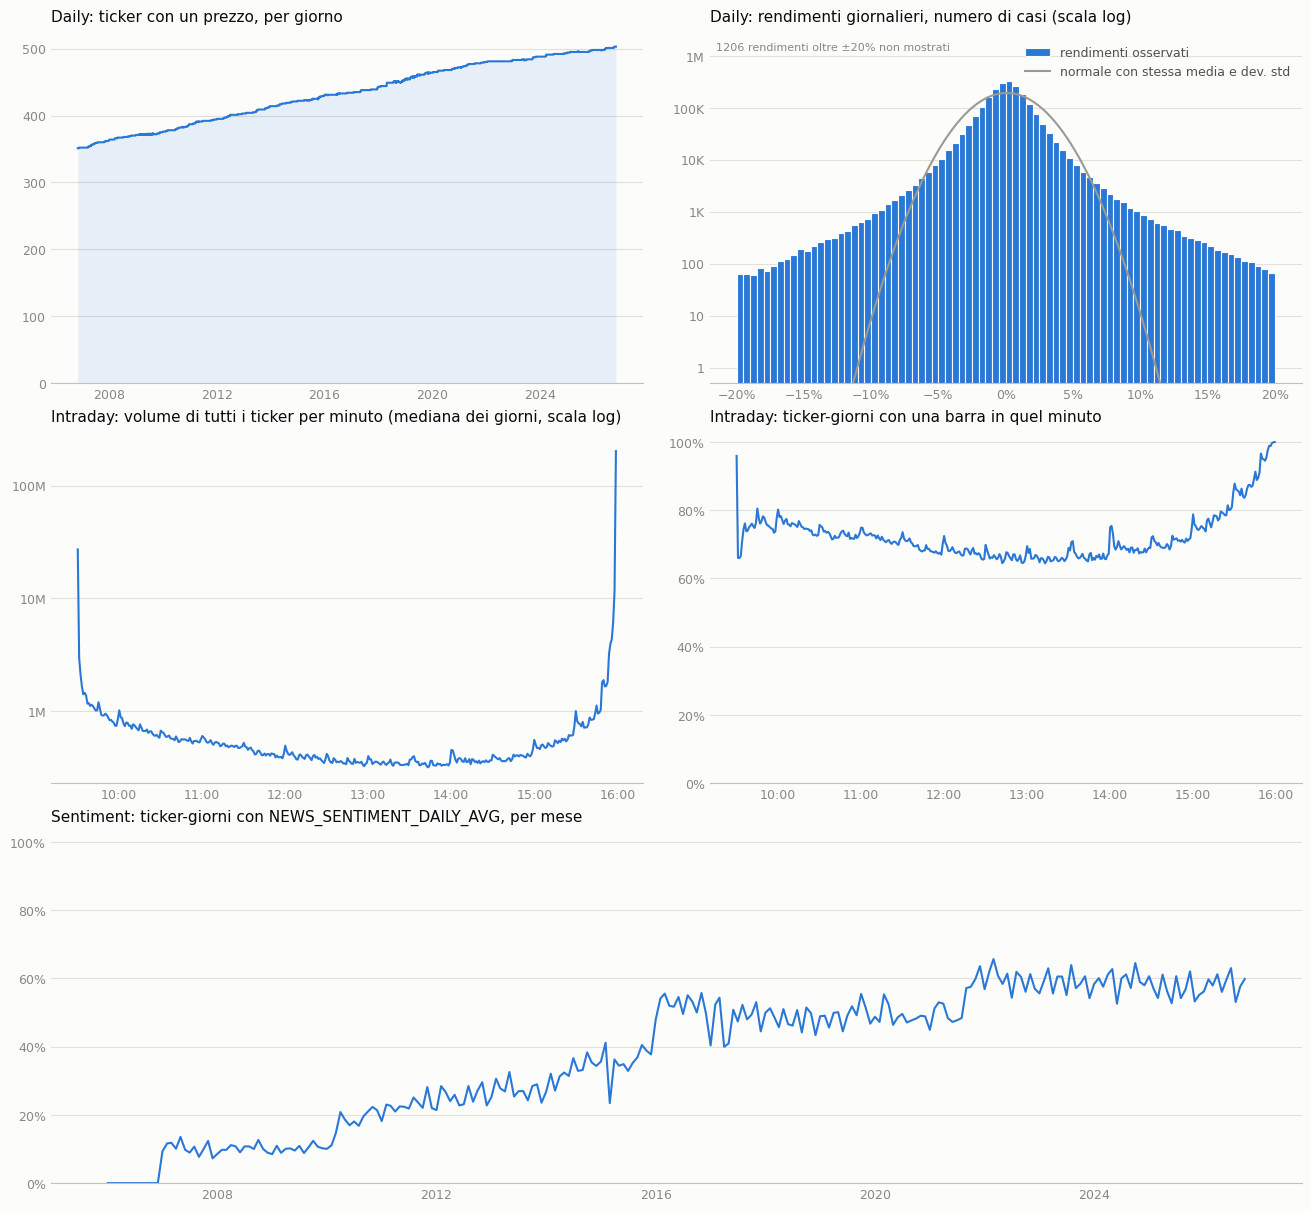

In [19]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, PercentFormatter

# palette del progetto (gli stessi 8 colori, nello stesso ordine, di src/plots.py) e colori neutri per testo, griglia e assi
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
BLUE, REFERENCE = PALETTE[0], "#9a9992"
SURFACE, INK, INK_2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
LW = 1.5
compact = FuncFormatter(lambda v, _: f"{v / 1e6:,.0f}M" if v >= 1e6 else f"{v / 1e3:,.0f}K" if v >= 1e3 else f"{v:,.0f}")
percent = PercentFormatter(1, decimals=0)

def style(ax, title):
    ax.set_facecolor(SURFACE)
    ax.set_title(title, loc="left", color=INK, fontsize=11, pad=10)
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(AXIS)
    ax.tick_params(which="both", colors=MUTED, labelsize=9, length=0)

def minute_axis(ax, index):
    """Converte gli orari (datetime.time) in minuti dalla mezzanotte, con un'etichetta per ogni ora."""
    ticks = range(10 * 60, 16 * 60 + 1, 60)
    ax.set_xticks(ticks, [f"{m // 60}:00" for m in ticks])
    return [t.hour * 60 + t.minute for t in index]

fig, axes = plt.subplot_mosaic(
    [["coverage", "returns"], ["volume", "bars"], ["sentiment", "sentiment"]],
    figsize=(13, 12), facecolor=SURFACE, layout="constrained")

# 1. l'universo sono i titoli dell'indice di oggi: chi è entrato dopo il 2006 manca all'inizio
ax = axes["coverage"]
coverage = daily.dropna(subset=["PX_LAST"]).groupby("date").size()
ax.plot(coverage.index, coverage.values, color=BLUE, lw=LW)
ax.fill_between(coverage.index, coverage.values, color=BLUE, alpha=0.1, lw=0)
ax.set_ylim(0, 520)
style(ax, "Daily: ticker con un prezzo, per giorno")

# 2. code grasse: i rendimenti estremi sono molto più frequenti che in una normale
ax = axes["returns"]
r = daily["ret"].dropna()  # dalla cella dei controlli: solo tra giorni di borsa consecutivi
bins = np.linspace(-0.2, 0.2, 81)
ax.hist(r[r.abs() <= 0.2], bins=bins, color=BLUE, edgecolor=SURFACE, linewidth=0.8, label="rendimenti osservati")
x = np.linspace(-0.2, 0.2, 400)
normal = len(r) * (bins[1] - bins[0]) * np.exp(-0.5 * ((x - r.mean()) / r.std()) ** 2) / (r.std() * np.sqrt(2 * np.pi))
ax.plot(x, normal, color=REFERENCE, lw=LW, label="normale con stessa media e dev. std")
ax.set_yscale("log")
ax.set_ylim(0.5, None)
ax.yaxis.set_major_formatter(compact)
ax.xaxis.set_major_formatter(percent)
ax.legend(frameon=False, labelcolor=INK_2, fontsize=9, loc="upper right")
ax.text(0.01, 0.98, f"{(r.abs() > 0.2).sum()} rendimenti oltre ±20% non mostrati", transform=ax.transAxes, va="top", color=MUTED, fontsize=8)
style(ax, "Daily: rendimenti giornalieri, numero di casi (scala log)")

# 3. profilo della giornata: volume alto in apertura e in chiusura
#    il primo e l'ultimo minuto contengono le aste di apertura e chiusura: senza scala log schiaccerebbero il resto
ax = axes["volume"]
volume = intraday.groupby(["date", "time"], observed=True)["volume"].sum().groupby(level="time", observed=True).median()
ax.plot(minute_axis(ax, volume.index), volume.values, color=BLUE, lw=LW)
ax.set_yscale("log")
ax.yaxis.set_major_formatter(compact)
style(ax, "Intraday: volume di tutti i ticker per minuto (mediana dei giorni, scala log)")

# 4. completezza: in quali minuti mancano più barre
ax = axes["bars"]
present = intraday.groupby("time", observed=True).size() / intraday.groupby(["ticker", "date"], observed=True).ngroups
ax.plot(minute_axis(ax, present.index), present.values, color=BLUE, lw=LW)
ax.set_ylim(0, 1.02)
ax.yaxis.set_major_formatter(percent)
style(ax, "Intraday: ticker-giorni con una barra in quel minuto")

# 5. copertura del sentiment nel tempo, solo mesi completi (dopo l'ultimo giorno di borsa il file è vuoto)
ax = axes["sentiment"]
s = sentiment[sentiment["date"] < daily["date"].max().replace(day=1)]
covered = s["NEWS_SENTIMENT_DAILY_AVG"].notna().groupby(s["date"].dt.to_period("M")).mean()
ax.plot(covered.index.to_timestamp(), covered.values, color=BLUE, lw=LW)
ax.set_ylim(0, 1.02)
ax.yaxis.set_major_formatter(percent)
style(ax, "Sentiment: ticker-giorni con NEWS_SENTIMENT_DAILY_AVG, per mese")

plt.show()

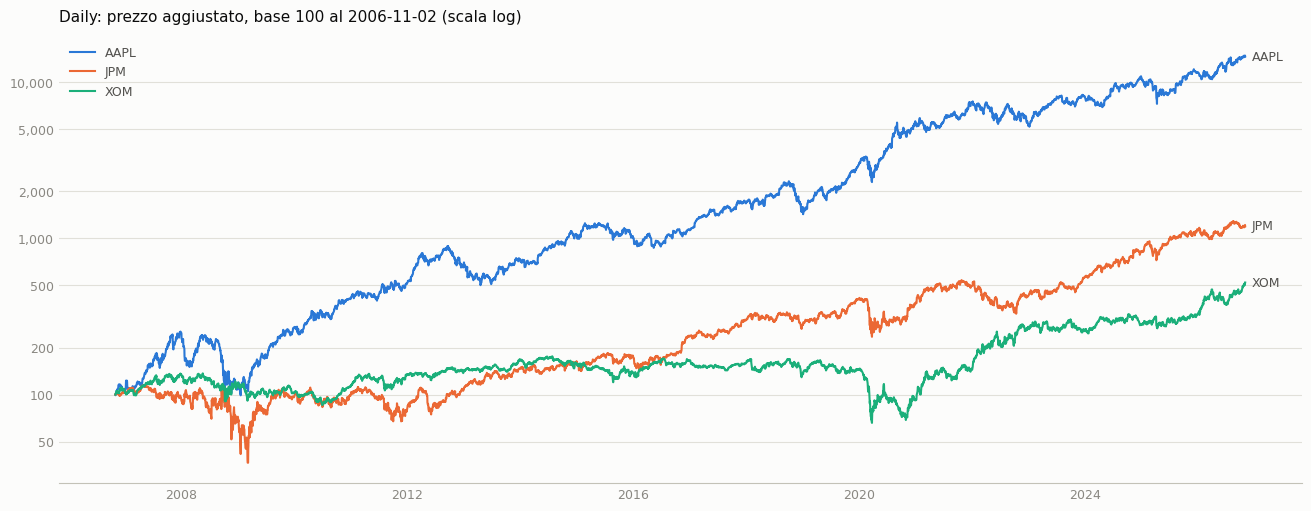

In [20]:
from matplotlib.ticker import LogLocator, NullFormatter

# ticker da confrontare: cambia la lista e riesegui la cella
# basta il nome breve ("AAPL") o quello completo ("AAPL UW Equity"); al massimo 8, uno per colore della palette
TICKERS = ["AAPL", "JPM", "XOM"]

full_name = {t.split()[0]: t for t in daily["ticker"].cat.categories}
names = [t.split()[0] for t in TICKERS]
missing = [n for n in names if n not in full_name]
if missing:
    raise ValueError(f"ticker non presenti nel daily: {missing}")
if len(names) > len(PALETTE):
    raise ValueError(f"al massimo {len(PALETTE)} ticker, uno per colore della palette")

# base 100 nel primo giorno in cui tutti hanno un prezzo, così i ticker entrati dopo sono confrontabili
prices = pd.DataFrame({n: daily.loc[daily["ticker"] == full_name[n]].set_index("date")["PX_LAST"] for n in names})
start = prices.dropna().index[0]
prices = prices.loc[start:] / prices.loc[start] * 100

fig, ax = plt.subplots(figsize=(13, 5), facecolor=SURFACE, layout="constrained")
for (name, s), color in zip(prices.items(), PALETTE):
    ax.plot(s.index, s.values, color=color, lw=LW, label=name)  # i buchi nella serie restano interruzioni della linea
    last = s.dropna()
    ax.annotate(name, (last.index[-1], last.iloc[-1]), xytext=(5, 0), textcoords="offset points", va="center", color=INK_2, fontsize=9)
ax.set_yscale("log")
ax.yaxis.set_major_locator(LogLocator(subs=(1, 2, 5)))  # etichette a 1, 2, 5, 10, 20, 50...
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.yaxis.set_minor_formatter(NullFormatter())
ax.legend(frameon=False, labelcolor=INK_2, fontsize=9, loc="upper left")
style(ax, f"Daily: prezzo aggiustato, base 100 al {start.date()} (scala log)")
plt.show()